11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training data shape : (60000, 28, 28)
Training labels shape: (60000,)
Test data shape     : (10000, 28, 28)
Test labels shape   : (10000,)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,890 (511.29 KB)

 Trainable params: 130,890 (511.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 52s 58ms/step - accuracy: 0.9199 - loss: 0.2539 - val_accuracy: 0.9882 - val_loss: 0.0415
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 82s 58ms/step - accuracy: 0.9783 - loss: 0.0749 - val_accuracy: 0.9893 - val_loss: 0.0348
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 78s 53ms/step - accuracy: 0.9850 - loss: 0.0534 - val_accuracy: 0.9878 - val_loss: 0.0428
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 44s 53ms/step - accuracy: 0.9877 - loss: 0.0416 - val_accuracy: 0.9878 - val_loss: 0.0340
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 83s 54ms/step - accuracy: 0.9900 - loss: 0.0339 - val_accuracy: 0.9893 - val_loss: 0.0352
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 44s 52ms/step - accuracy: 0.9911 - loss: 0.0298 - val_accuracy: 0.9908 - val_loss: 0.0314
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 45s 53ms/step - accuracy: 0.9926 - loss: 0.0242 - val_accuracy: 0.9925 - val_loss: 0.0271
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 45s 53ms/step - accuracy: 0.9929 - loss: 0.0216 - 

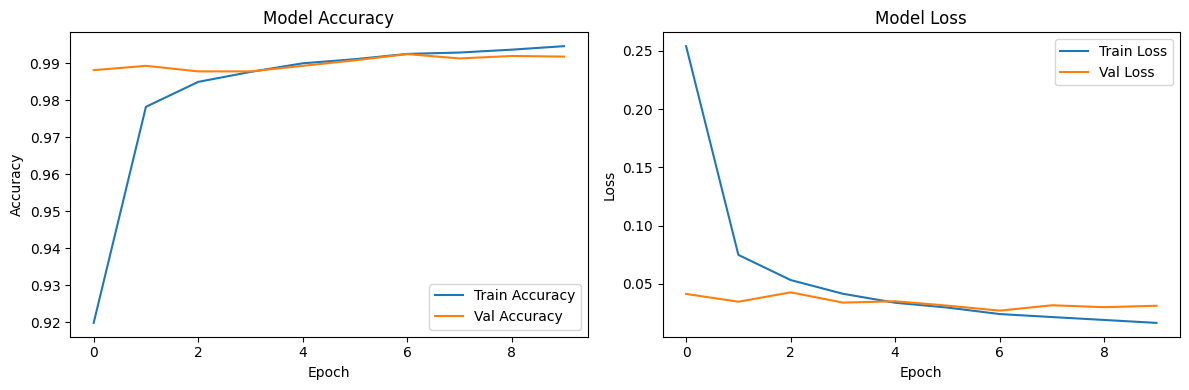

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
Sample 1: Predicted = 7, Actual = 7
Sample 2: Predicted = 2, Actual = 2
Sample 3: Predicted = 1, Actual = 1
Sample 4: Predicted = 0, Actual = 0
Sample 5: Predicted = 4, Actual = 4


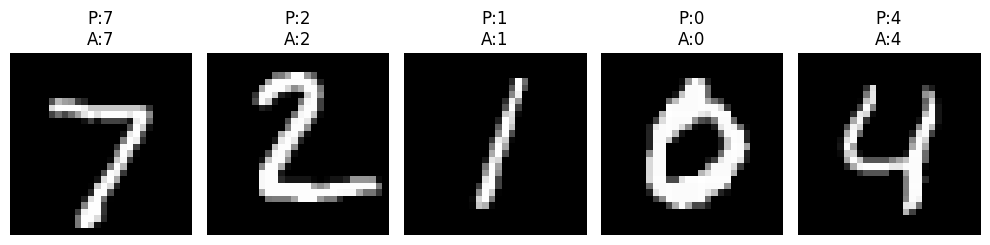

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt
import numpy as np

(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training data shape :", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Test data shape     :", x_test.shape)
print("Test labels shape   :", y_test.shape)

x_train = x_train.astype('float32') / 255.0
x_test  = x_test.astype('float32')  / 255.0

x_train = x_train.reshape(-1, 28, 28, 1)
x_test  = x_test.reshape(-1, 28, 28, 1)

y_train = to_categorical(y_train, 10)
y_test  = to_categorical(y_test, 10)

model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

model.summary()

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print(f"\nTest Accuracy: {test_acc:.4f}")
print(f"Test Loss    : {test_loss:.4f}")

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

predictions = model.predict(x_test[:5])

for i in range(5):
    predicted_label = np.argmax(predictions[i])
    true_label = np.argmax(y_test[i])
    print(f"Sample {i+1}: Predicted = {predicted_label}, Actual = {true_label}")

plt.figure(figsize=(10, 3))
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title(f"P:{np.argmax(predictions[i])}\nA:{np.argmax(y_test[i])}")
    plt.axis('off')
plt.tight_layout()
plt.show()

1. The code imports TensorFlow, Keras layers, the MNIST dataset, `to_categorical`, matplotlib, and numpy to build a CNN for handwritten digit recognition.

2. `mnist.load_data()` loads 60,000 training images and 10,000 test images of 28×28 pixel digits along with their labels.

3. Preprocessing divides pixel values by 255.0 to scale them between 0 and 1, reshapes images to (28, 28, 1) for the CNN, and one-hot encodes the labels into 10-element vectors.

4. The model is built using `Sequential`, which stacks layers one after another in a straight line.

5. Three `Conv2D` layers with ReLU activation detect features like edges and curves, while `MaxPooling2D` layers shrink the image size to reduce computation.

6. `Flatten()` converts the 3D feature maps into a 1D vector, `Dense(128)` learns high-level patterns, `Dropout(0.5)` prevents overfitting, and `Dense(10, softmax)` outputs probabilities for the 10 digits.

7. `model.compile()` sets the Adam optimizer, categorical crossentropy loss, and accuracy metric for training.

8. `model.fit()` trains the network for 10 epochs with a batch size of 64 and uses 10% of the training data for validation.

9. `model.evaluate()` checks the model on unseen test data, usually giving about 99% accuracy, and the plots show training vs validation accuracy and loss.

10. `model.predict()` classifies new images, `np.argmax` picks the highest-probability digit, and `plt.imshow()` displays test images with their predicted and actual labels for comparison.